# Task 2: Negative Review Detection (Tom)

**Question.** Given a (user, recipe) interaction on Food.com, can we tell whether the user's rating is *negative*?

We define a review as **negative if its star rating is ≤ 3** (1, 2 or 3 stars). On Food.com almost everything is 4–5 stars, so a 3-star rating is already a clear signal of dissatisfaction (3-star reviews typically say "it was OK but...").

We study the task in two settings, which answer two different practical questions:

| Setting | Input | Practical use |
|---|---|---|
| **A. Before the review (no text)** | user history, recipe history, recipe content (time, steps, ingredients, nutrition, tags), date | "Is this user likely to dislike this recipe?" → don't recommend it / warn the user |
| **B. From the review text** | the written review (+ the Setting A features) | sentiment analysis → flag unhappy reviews for the recipe author or for moderation; catch negatives that would otherwise be hidden among 5-star reviews |

All numbers below use the group's filtered split (`filtered_train / validation / test.csv`, 80/10/10). Hyperparameters and decision thresholds are chosen **on validation only**; the test set is used once, at the end.

## 0. Setup

In [1]:
import ast, re, time, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             roc_curve, accuracy_score)

SEED = 0
random.seed(SEED); np.random.seed(SEED)
DATA_PATH = "../dataset/"
plt.rcParams.update({"figure.figsize": (6, 3.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 4)

## 1. Data and label

We reuse the group's pre-processing (0-star ratings removed, users with ≥ 4 reviews, recipes with 5 min–1 day cooking time, 3–40 steps, 3–18 ingredients) and its 80/10/10 random split.

In [2]:
train = pd.read_csv(DATA_PATH + "filtered_train.csv")
valid = pd.read_csv(DATA_PATH + "filtered_validation.csv")
test  = pd.read_csv(DATA_PATH + "filtered_test.csv")
recipes = pd.read_csv(DATA_PATH + "filtered_recipes.csv")

for d in (train, valid, test):
    d["review"] = d["review"].fillna("").astype(str)
    d["y"] = (d["rating"] <= 3).astype(int)          # 1 = negative review
    d["date"] = pd.to_datetime(d["date"])

summary = pd.DataFrame({
    name: {"interactions": len(d), "users": d.user_id.nunique(), "recipes": d.recipe_id.nunique(),
           "negative (≤3★)": d.y.sum(), "% negative": 100 * d.y.mean()}
    for name, d in [("train", train), ("validation", valid), ("test", test)]}).T
summary

,interactions,users,recipes,negative (≤3★),% negative
train,631414.0,25527.0,171941.0,34692.0,5.4943
validation,78927.0,16065.0,48373.0,4347.0,5.5076
test,78927.0,16076.0,48091.0,4189.0,5.3074


In [3]:
print("users in valid/test seen in train : %.2f%% / %.2f%%" % (100*valid.user_id.isin(train.user_id).mean(),
                                                             100*test.user_id.isin(train.user_id).mean()))
print("recipes in valid/test seen in train: %.2f%% / %.2f%%" % (100*valid.recipe_id.isin(train.recipe_id).mean(),
                                                             100*test.recipe_id.isin(train.recipe_id).mean()))
print("majority-class accuracy on test (always predict 'not negative'): %.4f" % (1 - test.y.mean()))

users in valid/test seen in train : 99.99% / 99.98%
recipes in valid/test seen in train: 87.13% / 87.30%
majority-class accuracy on test (always predict 'not negative'): 0.9469


**Take-away:** only ~5.5% of reviews are negative. A classifier that always says "not negative" is ~94.5% accurate and completely useless, so **accuracy is not a sensible metric here** (see Section 3). Almost every test user was seen in training, but ~13% of test recipes were not (cold-start recipes).

## 2. Exploratory analysis for this task

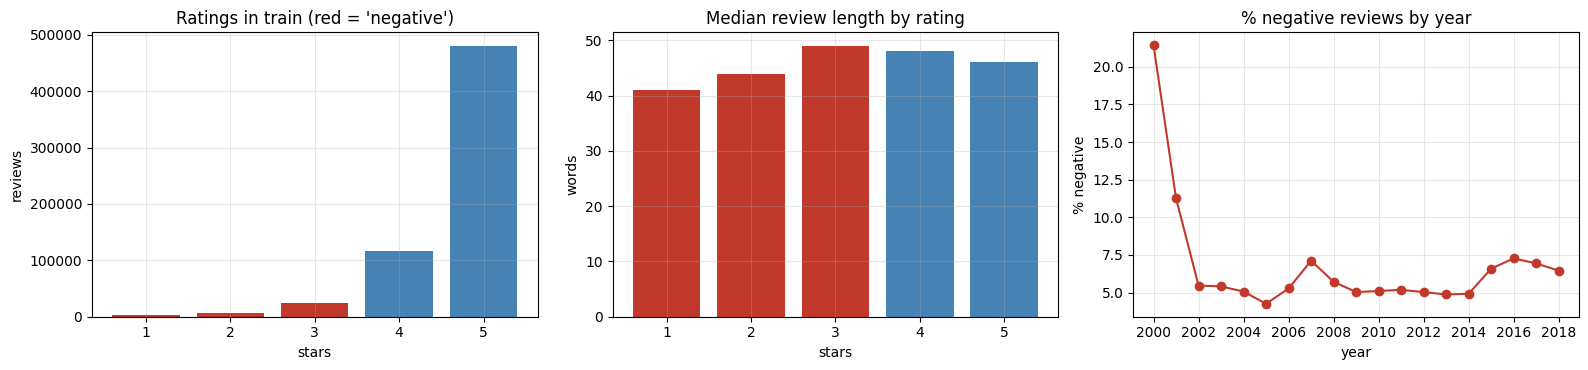

,reviews,median_words,mean_exclamation_marks,share_with_exclamation
rating,,,,
1,3643,41.0,0.31,0.18
2,6746,44.0,0.24,0.16
3,24303,49.0,0.34,0.23
4,116467,48.0,0.88,0.49
5,480255,46.0,1.78,0.71


In [4]:
train["n_words"] = train.review.str.split().str.len()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))

vc = train.rating.value_counts().sort_index()
ax[0].bar(vc.index, vc.values, color=["#c0392b"]*3 + ["steelblue"]*2)
ax[0].set_title("Ratings in train (red = 'negative')"); ax[0].set_xlabel("stars"); ax[0].set_ylabel("reviews")

med = train.groupby("rating").n_words.median()
ax[1].bar(med.index, med.values, color=["#c0392b"]*3 + ["steelblue"]*2)
ax[1].set_title("Median review length by rating"); ax[1].set_xlabel("stars"); ax[1].set_ylabel("words")

year_rate = train.groupby(train.date.dt.year).y.mean() * 100
ax[2].plot(year_rate.index, year_rate.values, marker="o", color="#c0392b")
ax[2].set_title("% negative reviews by year"); ax[2].set_xlabel("year"); ax[2].set_ylabel("% negative")
ax[2].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

train["n_excl"] = train.review.str.count("!")
train.groupby("rating").agg(reviews=("y", "size"), median_words=("n_words", "median"),
                            mean_exclamation_marks=("n_excl", "mean"),
                            share_with_exclamation=("n_excl", lambda x: (x > 0).mean())).round(2)

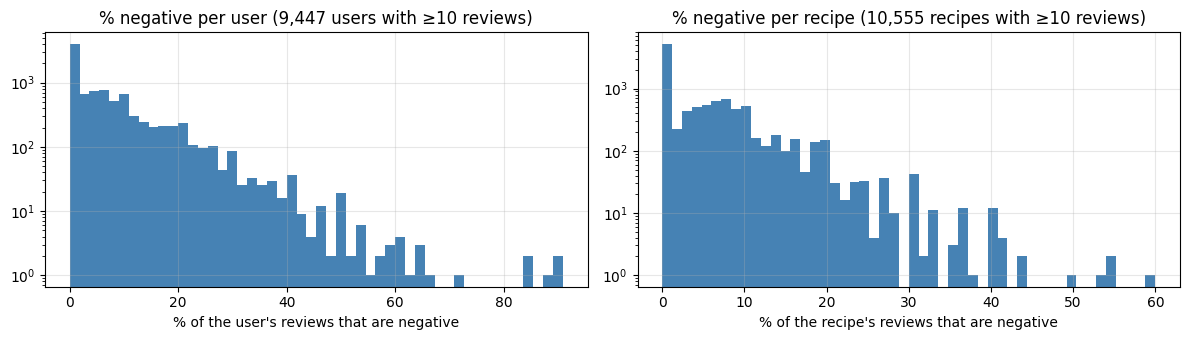

users with >=10 reviews: 38.7% never gave a negative rating; 8.3% gave >20% negatives


In [5]:
# Are some users "habitual critics" and some recipes "bad recipes"?
u = train.groupby("user_id").y.agg(["mean", "size"]).query("size >= 10")
r = train.groupby("recipe_id").y.agg(["mean", "size"]).query("size >= 10")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(u["mean"]*100, bins=50, color="steelblue"); ax[0].set_yscale("log")
ax[0].set_title(f"% negative per user ({len(u):,} users with ≥10 reviews)"); ax[0].set_xlabel("% of the user's reviews that are negative")
ax[1].hist(r["mean"]*100, bins=50, color="steelblue"); ax[1].set_yscale("log")
ax[1].set_title(f"% negative per recipe ({len(r):,} recipes with ≥10 reviews)"); ax[1].set_xlabel("% of the recipe's reviews that are negative")
plt.tight_layout(); plt.show()
print("users with >=10 reviews: %.1f%% never gave a negative rating; %.1f%% gave >20%% negatives"
      % (100*(u["mean"] == 0).mean(), 100*(u["mean"] > 0.2).mean()))

In [6]:
# A few example reviews per star level
pd.set_option("display.max_colwidth", 160)
ex = (train[train.n_words.between(8, 30)].groupby("rating", group_keys=False)
      .apply(lambda g: g.sample(2, random_state=SEED))[["rating", "review"]])
ex

,rating,review
537707,1,"Had an odd flavor, almost like cheddar cheese"
13092,1,Flavors were just off and with the price of meat it was hard to have to toss them out.
526537,2,"The best thing about this receipe is the low calories. I ""might"" make it again, but I doubt it."
77754,2,The nutmeg didn't seem to blend withthe dill. I wouldn't make it again.
79139,3,Way too much oil and sugar for us. Thought I would give it a go because of the stellar reviews. Just not a great fit for our house.
593092,3,"This was okay but lacked the flavor we were hoping for with these great reviews. A large amount went uneaten, even after taking it to work, where they'll e..."
105096,4,YUMMM....I topped this off with vanilla ice cream..
622609,4,"These were delicious and I loved them but my partner didn&#039;t, which was ok because I got two then :)"
289539,5,"Very good, you don't have to worry about hot oil for frying! I put in a warm oven with a towel over when the dough is rising. Shortens the time."
52199,5,Absolutely Fabulous & I'm not even a huge fan of raisins.....<br/>Great job as usual Kittencal<br/>; )


**Observations that shape the models**

* Review **length** differs only a little between star levels (3★ reviews are the longest, 1–2★ the shortest), but **exclamation marks** are much more common in 4–5★ reviews ("Delicious!!") → length and "!" count form a simple non-lexical baseline.
* The negative rate **changes over time**: very high in 2000–2001 (the early site), ~5% for most years, rising to ~7% after 2015 → the review year is a feature.
* Users differ a lot: most never give a negative rating while a small group gives many; the same holds for recipes. → **user and recipe "negativity priors"** should be strong features in Setting A (this is the classification analogue of the user/item bias terms of the latent-factor model from the recommendation lectures).
* 3-star reviews often contain positive words ("good", "nice") together with criticism ("but", "too salty") — they will be the hardest cases for a bag-of-words model.

## 3. Predictive task, evaluation and baselines

* **Input:** (user, recipe, date) [+ review text in Setting B]. **Output:** a score $p(\text{negative}\mid x)$ and a yes/no decision. **Optimised:** regularised log-likelihood (logistic regression), with **class-balanced weights** so the 5.5% minority class is not ignored (classification lecture: "when data are highly imbalanced, assign additional weight to the rare class").
* **Metrics** (why not accuracy: see above):
  * **ROC-AUC** – probability a random negative review is scored above a random positive one; threshold-free and insensitive to the class ratio.
  * **Average precision (AP, area under the precision/recall curve)** – our main metric; unlike AUC it focuses on the rare class, so it is the right metric when we care about *finding* negatives. The random baseline is the prevalence (~0.055).
  * **Precision@1000** – the ranking view: if a moderator can read only 1,000 reviews flagged by the model, how many are really negative?
  * **BER** (balanced error rate, ½(FPR+FNR)) and **F1 / precision / recall** at a decision threshold. Thresholds are picked on the validation set (BER-optimal and F1-optimal respectively), never on test.
* **Baselines:** (1) constant predictor (= always "not negative"), (2) user's historical negative rate only, (3) recipe's historical negative rate only, (4) review length + exclamation-mark count only (Setting B).
* **Validity:** strict train/validation/test separation; user/recipe statistics are computed from training data only, and for training rows **leave-one-out** (the row's own label is removed) so the model cannot learn from a feature that contains its own answer. We also check the predictions by star level, inspect the learned word weights and read misclassified examples (Section 6).

In [7]:
def best_thresholds(y, s):
    # Choose decision thresholds on VALIDATION scores.
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p * r / np.maximum(p + r, 1e-12)
    t_f1 = t[np.argmax(f1[:-1])] if len(t) else 0.5
    fpr, tpr, tr = roc_curve(y, s)
    t_ber = tr[np.argmin(0.5 * (fpr + 1 - tpr))]
    return t_f1, t_ber

def metrics_at(y, s, t_f1, t_ber, k=1000):
    yhat = s >= t_f1
    tp = (yhat & (y == 1)).sum()
    prec = tp / max(yhat.sum(), 1); rec = tp / (y == 1).sum()
    yb = s >= t_ber
    fpr = (yb & (y == 0)).sum() / (y == 0).sum(); fnr = (~yb & (y == 1)).sum() / (y == 1).sum()
    top = np.argsort(-s, kind="stable")[:k]
    return {"AUC": roc_auc_score(y, s), "AP": average_precision_score(y, s),
            f"P@{k}": y[top].mean(), "BER": 0.5 * (fpr + fnr),
            "Precision": prec, "Recall": rec, "F1": 2 * prec * rec / max(prec + rec, 1e-12)}

RESULTS, SCORES = [], {}
y_tr, y_va, y_te = train.y.values, valid.y.values, test.y.values

def report(name, setting, s_va, s_te):
    # thresholds from validation, metrics on validation and test
    t_f1, t_ber = best_thresholds(y_va, s_va)
    va = metrics_at(y_va, s_va, t_f1, t_ber); te = metrics_at(y_te, s_te, t_f1, t_ber)
    RESULTS.append({"setting": setting, "model": name, "val AP": va["AP"], **te})
    SCORES[name] = (s_va, s_te)
    print(f"{name:45s} val AUC {va['AUC']:.4f} AP {va['AP']:.4f} | test AUC {te['AUC']:.4f} AP {te['AP']:.4f} BER {te['BER']:.4f} F1 {te['F1']:.4f}")

## 4. Setting A — predicting a negative rating *before* the review is written

### 4.1 Features
For an interaction (u, i, date):

* **User prior:** smoothed share of u's training reviews that are negative, $\hat p_u = \frac{\#neg_u + \alpha\,\bar p}{n_u + \alpha}$ (shrinks users with few reviews towards the global rate $\bar p$), plus $\log(1+n_u)$ and u's mean star rating.
* **Recipe prior:** the same for recipe i (unseen recipes get $\bar p$ and $n_i = 0$, i.e. cold start).
* **Recipe content:** log cooking time, #steps, #ingredients, the 7 nutrition values (log-scaled), and one-hot indicators for the 60 most common tags (cuisine, course, dietary, ...).
* **Context:** review year.

For training rows the user/recipe statistics are computed **leave-one-out**; otherwise e.g. a recipe reviewed once would have a prior equal to its own label, and the model would look excellent in training and fail on new data.

In [8]:
ALPHA = 5.0
p0 = train.y.mean()
mu0 = train.rating.mean()

def group_stats(key):
    g = train.groupby(key).agg(n=("y", "size"), neg=("y", "sum"), rsum=("rating", "sum"))
    return g

def prior_features(df, key, prefix, is_train):
    g = group_stats(key)
    m = df[[key]].join(g, on=key)
    n, neg, rsum = m.n.fillna(0).values, m.neg.fillna(0).values, m.rsum.fillna(0).values
    if is_train:                                   # leave-one-out
        n, neg, rsum = n - 1, neg - df.y.values, rsum - df.rating.values
    return pd.DataFrame({
        f"{prefix}_neg_rate": (neg + ALPHA * p0) / (n + ALPHA),
        f"{prefix}_mean_rating": (rsum + ALPHA * mu0) / (n + ALPHA),
        f"{prefix}_log_n": np.log1p(n),
        f"{prefix}_unseen": (n == 0).astype(float)}, index=df.index)

# --- recipe content features ---
rec = recipes[recipes.id.isin(set(train.recipe_id) | set(valid.recipe_id) | set(test.recipe_id))].copy()
rec["tags_l"] = rec.tags.apply(ast.literal_eval)
nut = np.array(rec.nutrition.apply(ast.literal_eval).tolist())
nut_names = ["calories", "total_fat", "sugar", "sodium", "protein", "sat_fat", "carbs"]
tag_counts = Counter(t for ts in rec.tags_l for t in ts)
TOP_TAGS = [t for t, _ in tag_counts.most_common(80) if t not in ("time-to-make", "course", "preparation",
            "main-ingredient", "dietary", "occasion", "cuisine", "equipment", "number-of-servings")][:60]
rec_feat = pd.DataFrame({"log_minutes": np.log1p(rec.minutes.values),
                         "n_steps": rec.n_steps.values, "n_ingredients": rec.n_ingredients.values},
                        index=rec.id.values)
for j, nme in enumerate(nut_names):
    rec_feat["log_" + nme] = np.log1p(np.clip(nut[:, j], 0, None))
tagset = rec.tags_l.apply(set).values
for t in TOP_TAGS:
    rec_feat["tag_" + t] = [float(t in s) for s in tagset]

def build_A(df, is_train):
    X = pd.concat([prior_features(df, "user_id", "user", is_train),
                   prior_features(df, "recipe_id", "recipe", is_train),
                   rec_feat.reindex(df.recipe_id.values).set_index(df.index)], axis=1)
    X["year"] = df.date.dt.year.values
    return X

XA_tr, XA_va, XA_te = build_A(train, True), build_A(valid, False), build_A(test, False)
print(XA_tr.shape, "| a few columns:", list(XA_tr.columns[:12]))
XA_tr.describe().T.head(12)

(631414, 79) | a few columns: ['user_neg_rate', 'user_mean_rating', 'user_log_n', 'user_unseen', 'recipe_neg_rate', 'recipe_mean_rating', 'recipe_log_n', 'recipe_unseen', 'log_minutes', 'n_steps', 'n_ingredients', 'log_calories']


,count,mean,std,min,25%,50%,75%,max
user_neg_rate,631414.0,0.0528,0.0654,0.0002,0.0114,0.0295,0.0671,0.7508
user_mean_rating,631414.0,4.6878,0.2341,2.4278,4.5736,4.7454,4.8568,4.9982
user_log_n,631414.0,4.6994,1.8939,0.0000,3.1781,4.7791,6.2860,8.6183
user_unseen,631414.0,0.0002,0.0148,0.0000,0.0000,0.0000,0.0000,1.0000
recipe_neg_rate,631414.0,0.0521,0.0434,0.0013,0.0275,0.0392,0.0549,0.5275
recipe_mean_rating,631414.0,4.7014,0.1413,2.9417,4.6417,4.7244,4.8013,4.9775
recipe_log_n,631414.0,2.1670,1.5584,0.0000,1.0986,1.9459,3.1355,6.7558
recipe_unseen,631414.0,0.1270,0.3330,0.0000,0.0000,0.0000,0.0000,1.0000
log_minutes,631414.0,3.7402,0.9278,1.7918,3.2581,3.7136,4.1897,7.2731
n_steps,631414.0,9.5618,5.0240,3.0000,6.0000,8.0000,12.0000,40.0000


### 4.2 Baselines and logistic regression
Logistic regression (classification lecture) with balanced class weights and L2 regularisation; the regularisation strength $C$ is chosen by validation AP. Features are standardised so that one $C$ suits all of them.

In [9]:
report("Constant (always 'not negative')", "A: no text", np.zeros(len(valid)), np.zeros(len(test)))
report("User negative-rate prior", "A: no text", XA_va.user_neg_rate.values, XA_te.user_neg_rate.values)
report("Recipe negative-rate prior", "A: no text", XA_va.recipe_neg_rate.values, XA_te.recipe_neg_rate.values)

Constant (always 'not negative')              val AUC 0.5000 AP 0.0551 | test AUC 0.5000 AP 0.0531 BER 0.5000 F1 0.1008
User negative-rate prior                      val AUC 0.7612 AP 0.1796 | test AUC 0.7714 AP 0.1806 BER 0.2974 F1 0.2493
Recipe negative-rate prior                    val AUC 0.6149 AP 0.0828 | test AUC 0.6067 AP 0.0792 BER 0.4131 F1 0.1305


In [10]:
scA = StandardScaler().fit(XA_tr.values)
ZA_tr, ZA_va, ZA_te = scA.transform(XA_tr.values), scA.transform(XA_va.values), scA.transform(XA_te.values)

def fit_lr(Xtr, Xva, Cs, **kw):
    best = None
    for C in Cs:
        m = LogisticRegression(C=C, class_weight="balanced", max_iter=2000, **kw).fit(Xtr, y_tr)
        ap = average_precision_score(y_va, m.decision_function(Xva))
        print(f"   C={C:<6} val AP={ap:.4f}")
        if best is None or ap > best[0]: best = (ap, C, m)
    print("   -> best C =", best[1])
    return best[2]

lrA = fit_lr(ZA_tr, ZA_va, [0.001, 0.01, 0.1, 1.0])
report("Logistic regression (all no-text features)", "A: no text",
       lrA.decision_function(ZA_va), lrA.decision_function(ZA_te))

   C=0.001  val AP=0.2054


   C=0.01   val AP=0.2052


   C=0.1    val AP=0.2052


   C=1.0    val AP=0.2052
   -> best C = 0.001
Logistic regression (all no-text features)    val AUC 0.7977 AP 0.2054 | test AUC 0.7939 AP 0.1998 BER 0.2857 F1 0.2658


**Feature-group ablation.** Which information carries the signal? We refit the logistic regression on each group alone (same $C$).

In [11]:
groups = {"user prior": [c for c in XA_tr.columns if c.startswith("user_")],
          "recipe prior": [c for c in XA_tr.columns if c.startswith("recipe_")],
          "recipe content (time/steps/ingr./nutrition/tags)": [c for c in XA_tr.columns if not c.startswith(("user_", "recipe_")) and c != "year"]}
groups["user + recipe priors"] = groups["user prior"] + groups["recipe prior"]
abl = []
for gname, cols in groups.items():
    idx = [XA_tr.columns.get_loc(c) for c in cols]
    m = LogisticRegression(C=lrA.C, class_weight="balanced", max_iter=2000).fit(ZA_tr[:, idx], y_tr)
    s = m.decision_function(ZA_va[:, idx])
    abl.append({"features": gname, "#features": len(cols), "val AUC": roc_auc_score(y_va, s), "val AP": average_precision_score(y_va, s)})
abl.append({"features": "all", "#features": XA_tr.shape[1], "val AUC": roc_auc_score(y_va, lrA.decision_function(ZA_va)),
            "val AP": average_precision_score(y_va, lrA.decision_function(ZA_va))})
pd.DataFrame(abl)

,features,#features,val AUC,val AP
0,user prior,4,0.7678,0.1813
1,recipe prior,4,0.6362,0.0877
2,recipe content (time/steps/ingr./nutrition/tags),70,0.5774,0.0738
3,user + recipe priors,8,0.7957,0.2026
4,all,79,0.7977,0.2054


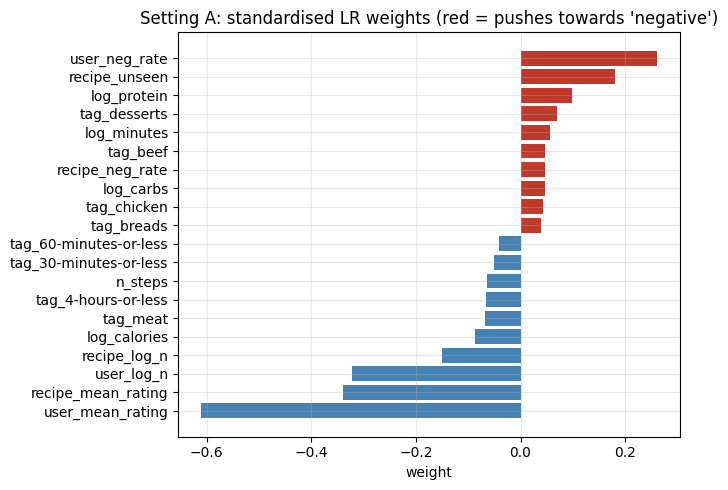

In [12]:
coefA = pd.Series(lrA.coef_[0], index=XA_tr.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
show = pd.concat([coefA.head(10), coefA.tail(10)])
ax.barh(show.index, show.values, color=["steelblue"]*10 + ["#c0392b"]*10)
ax.set_title("Setting A: standardised LR weights (red = pushes towards 'negative')"); ax.set_xlabel("weight")
plt.tight_layout(); plt.show()

**Non-linear comparison (outside the course models).** A gradient-boosted tree ensemble on the same features, to see whether interactions between features (e.g. a critical user × a long recipe) add anything a linear model misses.

In [13]:
t0 = time.time()
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_leaf_nodes=31,
                                    class_weight="balanced", random_state=SEED,
                                    early_stopping=True, validation_fraction=0.1)
gb.fit(XA_tr.values, y_tr)
print("fit in %.0fs, %d trees" % (time.time() - t0, gb.n_iter_))
report("Gradient boosted trees (no-text features)", "A: no text",
       gb.predict_proba(XA_va.values)[:, 1], gb.predict_proba(XA_te.values)[:, 1])

D:\python\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系统找不到指定的文件。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\python\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "D:\python\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\python\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "D:\python\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


fit in 14s, 300 trees


Gradient boosted trees (no-text features)     val AUC 0.7932 AP 0.1955 | test AUC 0.7900 AP 0.1879 BER 0.2892 F1 0.2573


## 5. Setting B — detecting negative reviews from the text

Following the text-mining lectures we represent each review as a **bag of words**:

1. **Bag-of-words, 1,000 most frequent unigrams** + logistic regression (exactly the lecture recipe).
2. **Naive Bayes** (multinomial) on unigram+bigram counts — "how far can we get just by counting?"
3. **TF-IDF unigrams + bigrams** + logistic regression. Bigrams recover some syntax ("not good", "too salty", "will not make"), TF-IDF down-weights words that appear everywhere ("recipe", "made").
4. **TF-IDF + Setting A features** (user/recipe priors, recipe content): does knowing *who* wrote the review and *about what* help beyond its words?

Pre-processing choices: lower-casing, the `<br/>` HTML tags removed, punctuation dropped by the tokenizer, **no stemming and no stop-word removal** — the lecture notes that stemming hurts predictive tasks, and standard stop-word lists contain "not", "no", "but", "too", which are among the most important words for negativity. Words appearing in fewer than 5 training reviews are discarded.

In [14]:
def clean(s):
    return s.str.replace(r"<br\s*/?>", " ", regex=True).str.lower()
txt_tr, txt_va, txt_te = clean(train.review), clean(valid.review), clean(test.review)

# Baseline: review length only
def len_feats(t):
    n = t.str.split().str.len().values
    return np.c_[np.log1p(n), t.str.count("!").values]
L_tr, L_va, L_te = len_feats(txt_tr), len_feats(txt_va), len_feats(txt_te)
lrL = LogisticRegression(class_weight="balanced").fit(L_tr, y_tr)
report("Review length + '!' count only", "B: text", lrL.decision_function(L_va), lrL.decision_function(L_te))

Review length + '!' count only                val AUC 0.7609 AP 0.1224 | test AUC 0.7634 AP 0.1225 BER 0.2728 F1 0.2037


In [15]:
# (1) Bag of words, top-1000 unigrams (lecture version)
t0 = time.time()
bow = CountVectorizer(max_features=1000)
B_tr = bow.fit_transform(txt_tr); B_va = bow.transform(txt_va); B_te = bow.transform(txt_te)
lrB = fit_lr(B_tr, B_va, [0.01, 0.1, 1.0], solver="liblinear")
report("BoW top-1000 unigrams + LR", "B: text", lrB.decision_function(B_va), lrB.decision_function(B_te))
print("%.0fs" % (time.time() - t0))

   C=0.01   val AP=0.6245


   C=0.1    val AP=0.6275


   C=1.0    val AP=0.6275
   -> best C = 1.0
BoW top-1000 unigrams + LR                    val AUC 0.9501 AP 0.6275 | test AUC 0.9521 AP 0.6231 BER 0.1128 F1 0.6048
71s


In [16]:
# (2) Naive Bayes on unigram + bigram counts
t0 = time.time()
cnt = CountVectorizer(ngram_range=(1, 2), min_df=5, max_features=200_000)
C_tr = cnt.fit_transform(txt_tr); C_va = cnt.transform(txt_va); C_te = cnt.transform(txt_te)
best = None
for a in [0.1, 0.5, 1.0]:
    nb = MultinomialNB(alpha=a).fit(C_tr, y_tr)
    ap = average_precision_score(y_va, nb.predict_log_proba(C_va)[:, 1] - nb.predict_log_proba(C_va)[:, 0])
    print(f"   alpha={a} val AP={ap:.4f}")
    if best is None or ap > best[0]: best = (ap, nb)
nb = best[1]
nb_score = lambda X: nb.predict_log_proba(X)[:, 1] - nb.predict_log_proba(X)[:, 0]
report("Naive Bayes (uni+bigram counts)", "B: text", nb_score(C_va), nb_score(C_te))
print("%.0fs" % (time.time() - t0))

   alpha=0.1 val AP=0.6521


   alpha=0.5 val AP=0.6467


   alpha=1.0 val AP=0.6454


Naive Bayes (uni+bigram counts)               val AUC 0.9535 AP 0.6521 | test AUC 0.9534 AP 0.6489 BER 0.1043 F1 0.6397
50s


In [17]:
# (3) TF-IDF unigrams + bigrams + logistic regression
t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=200_000, sublinear_tf=True)
T_tr = tfidf.fit_transform(txt_tr); T_va = tfidf.transform(txt_va); T_te = tfidf.transform(txt_te)
print("vocabulary:", len(tfidf.vocabulary_))
lrT = fit_lr(T_tr, T_va, [0.5, 2.0, 8.0], solver="liblinear")
report("TF-IDF uni+bigrams + LR", "B: text", lrT.decision_function(T_va), lrT.decision_function(T_te))
print("%.0fs" % (time.time() - t0))

vocabulary: 200000


   C=0.5    val AP=0.7512


   C=2.0    val AP=0.7619


   C=8.0    val AP=0.7562
   -> best C = 2.0
TF-IDF uni+bigrams + LR                       val AUC 0.9685 AP 0.7619 | test AUC 0.9696 AP 0.7602 BER 0.0893 F1 0.6994
114s


In [18]:
# (4) TF-IDF + Setting A features (standardised, scaled down so they live on a similar scale to TF-IDF entries)
t0 = time.time()
W = 0.1
H_tr = sp.hstack([T_tr, sp.csr_matrix(W * ZA_tr)]).tocsr()
H_va = sp.hstack([T_va, sp.csr_matrix(W * ZA_va)]).tocsr()
H_te = sp.hstack([T_te, sp.csr_matrix(W * ZA_te)]).tocsr()
lrH = fit_lr(H_tr, H_va, [2.0, 8.0], solver="liblinear")
report("TF-IDF + user/recipe/content features + LR", "B: text", lrH.decision_function(H_va), lrH.decision_function(H_te))
print("%.0fs" % (time.time() - t0))

   C=2.0    val AP=0.7871


   C=8.0    val AP=0.7819
   -> best C = 2.0
TF-IDF + user/recipe/content features + LR    val AUC 0.9741 AP 0.7871 | test AUC 0.9754 AP 0.7843 BER 0.0787 F1 0.7176
310s


## 6. Evaluation on the test set

All models below were tuned on validation; thresholds for BER and F1 were also fixed on validation. `val AP` is shown next to the test metrics to check that validation-based model selection transfers to test.

In [19]:
res = pd.DataFrame(RESULTS).set_index(["setting", "model"])
res.style.format("{:.3f}").background_gradient(subset=["AUC", "AP", "P@1000", "F1"], cmap="Greens") \
         .background_gradient(subset=["BER"], cmap="Greens_r")

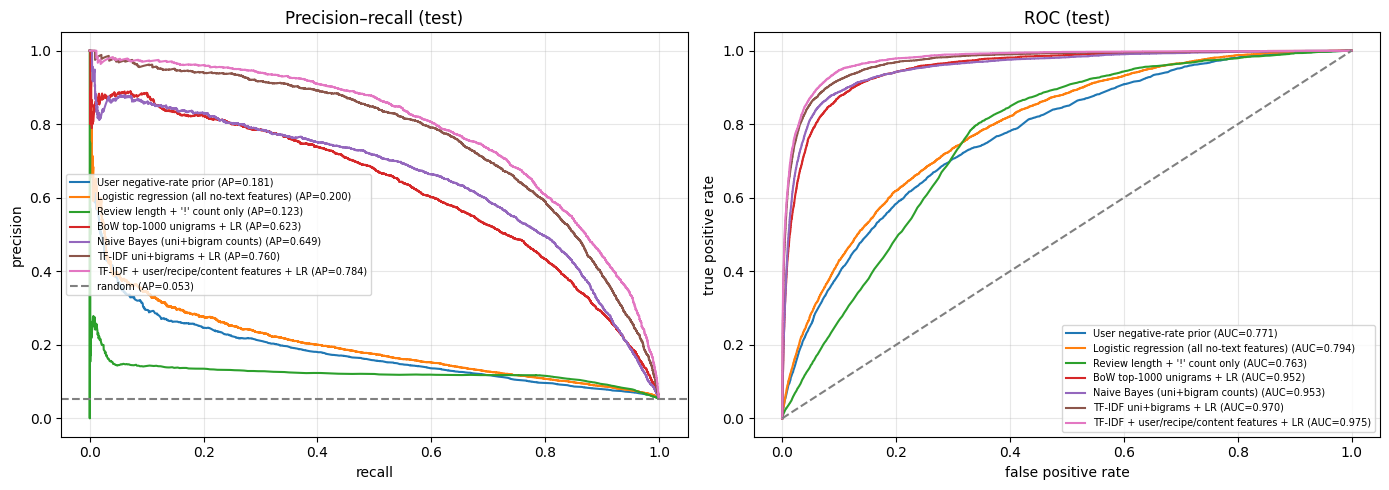

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
show = ["User negative-rate prior", "Logistic regression (all no-text features)", "Review length + '!' count only",
        "BoW top-1000 unigrams + LR", "Naive Bayes (uni+bigram counts)", "TF-IDF uni+bigrams + LR",
        "TF-IDF + user/recipe/content features + LR"]
for name in show:
    s = SCORES[name][1]
    p, r, _ = precision_recall_curve(y_te, s); fpr, tpr, _ = roc_curve(y_te, s)
    ax[0].plot(r, p, label=f"{name} (AP={average_precision_score(y_te, s):.3f})")
    ax[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_te, s):.3f})")
ax[0].axhline(y_te.mean(), ls="--", c="grey", label=f"random (AP={y_te.mean():.3f})")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision–recall (test)"); ax[0].legend(fontsize=7)
ax[1].plot([0, 1], [0, 1], "--", c="grey"); ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate")
ax[1].set_title("ROC (test)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 6.1 Validity checks for the best model

* Is the score monotone in the true star rating (are 1★ reviews scored as more negative than 3★)?
* Which star levels are caught at the F1-optimal threshold?
* Which words drive the decision, and what do the mistakes look like?

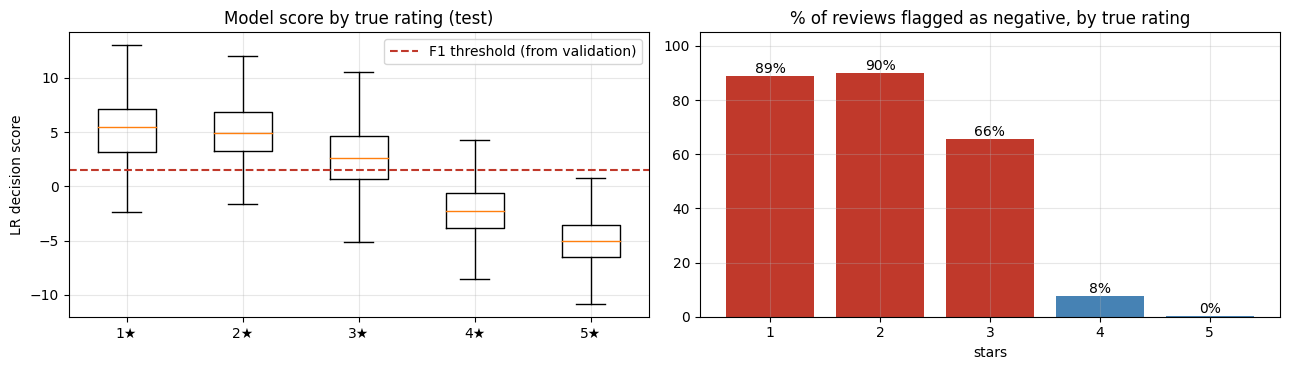

In [21]:
best_name = "TF-IDF + user/recipe/content features + LR"
s_va_b, s_te_b = SCORES[best_name]
t_f1, _ = best_thresholds(y_va, s_va_b)
tmp = test[["rating", "review"]].copy(); tmp["score"] = s_te_b; tmp["flagged"] = s_te_b >= t_f1

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
data = [tmp.score[tmp.rating == k].values for k in range(1, 6)]
ax[0].boxplot(data, labels=[f"{k}★" for k in range(1, 6)], showfliers=False)
ax[0].axhline(t_f1, ls="--", c="#c0392b", label="F1 threshold (from validation)"); ax[0].legend()
ax[0].set_title("Model score by true rating (test)"); ax[0].set_ylabel("LR decision score")
by = tmp.groupby("rating").flagged.mean() * 100
ax[1].bar(by.index, by.values, color=["#c0392b"]*3 + ["steelblue"]*2)
for k, v in by.items(): ax[1].text(k, v + 1, f"{v:.0f}%", ha="center")
ax[1].set_title("% of reviews flagged as negative, by true rating"); ax[1].set_xlabel("stars"); ax[1].set_ylim(0, 105)
plt.tight_layout(); plt.show()

In [22]:
vocab = np.array(tfidf.get_feature_names_out())
w = lrT.coef_[0]
order = np.argsort(w)
pd.DataFrame({"most 'negative' n-grams": vocab[order[::-1][:25]], "weight": w[order[::-1][:25]].round(2),
              "most 'positive' n-grams": vocab[order[:25]], "weight ": w[order[:25]].round(2)})

,most 'negative' n-grams,weight,most 'positive' n-grams,weight
0,sorry,16.96,delicious,-23.41
1,bland,13.91,wonderful,-17.77
2,ok,11.23,great,-15.62
3,three stars,10.73,thanks,-15.02
4,okay,10.41,perfect,-14.48
5,not,8.65,fantastic,-14.21
6,potential,8.64,excellent,-14.14
7,just didn,8.28,keeper,-13.09
8,thanks anyway,8.27,yummy,-13.07
9,was okay,7.87,awesome,-12.60


In [23]:
pd.set_option("display.max_colwidth", 220)
fn = tmp[(tmp.rating <= 3) & ~tmp.flagged & (tmp.review.str.split().str.len() < 45)].sort_values("score").head(6)
fp = tmp[(tmp.rating >= 4) & tmp.flagged & (tmp.review.str.split().str.len() < 45)].sort_values("score", ascending=False).head(6)
print("Missed negatives (false negatives):"); display(fn[["rating", "score", "review"]])
print("False alarms (false positives):");     display(fp[["rating", "score", "review"]])

Missed negatives (false negatives):


,rating,score,review
57262,3,-11.4693,Thanks.
48431,3,-11.1828,Wonderful! This is a real keeper. Thanks for posting.
28852,3,-7.5926,Yummy! And easy.
55266,3,-7.1246,Very tasty.
54192,3,-6.9345,this is great\r\n
77332,3,-5.9699,These were a good healthyish treat. I will definitely make them again. thanks for the recipe.


False alarms (false positives):


,rating,score,review
63897,4,11.2430,"It was good, but not great. I added cilantro, Rotel, black olives. It was just a little too mushy for us. The taste was good but the texture was just okay."
2311,4,10.8460,ok
36897,4,10.2605,"These were not difficult to put together, and the flavor was ok. They were just not for us. I used mozzarella cheese."
50355,4,9.0821,"I thought this was okay. And the family thought it was just okay, so we probably won't be making it again. But overall after draining off some water it was a quick and easy meal."
25100,4,8.8923,I liked the chicken but my DH said that it was just okay.
28465,4,8.2852,This was ok. The mustard was a little overpowering.


### 6.2 Sensitivity to the label definition
Is "≤ 3 stars" the right cut? We re-score the best model's test predictions against a stricter label (≤ 2 stars, i.e. clearly negative) without retraining.

In [24]:
y_strict = (test.rating <= 2).astype(int).values
mask_no3 = test.rating.values != 3
print("prevalence ≤2★: %.4f" % y_strict.mean())
print("AUC  for ≤2★ vs rest           : %.4f" % roc_auc_score(y_strict, s_te_b))
print("AP   for ≤2★ vs rest           : %.4f" % average_precision_score(y_strict, s_te_b))
print("AUC  for ≤2★ vs 4–5★ (3★ removed): %.4f" % roc_auc_score(y_strict[mask_no3], s_te_b[mask_no3]))
m3 = test.rating.values >= 3
print("AUC  for 3★ vs 4–5★ only        : %.4f" % roc_auc_score((test.rating.values[m3] == 3).astype(int), s_te_b[m3]))

prevalence ≤2★: 0.0159
AUC  for ≤2★ vs rest           : 0.9814
AP   for ≤2★ vs rest           : 0.4454
AUC  for ≤2★ vs 4–5★ (3★ removed): 0.9918
AUC  for 3★ vs 4–5★ only        : 0.9685


## 7. Discussion

**Headline numbers (test set).** Best no-text model: logistic regression, AUC 0.794 / AP 0.200 (random AP = 0.053). Best text model: TF-IDF uni+bigrams + user/recipe/content features + LR, **AUC 0.975 / AP 0.784 / P@1000 0.956 / BER 0.079 / F1 0.718**. Validation AP and test AP agree to within ~0.01 for every model, so model selection on validation transferred to test without overfitting.

**Setting A (no text).** Knowing only *who* is reviewing *which* recipe gives clearly better-than-random ranking (AUC ≈ 0.79, AP ≈ 4× random), but it is still a hard problem (F1 ≈ 0.27). The ablation shows that almost all of the signal is in the **user prior** (AUC 0.768 alone); the recipe prior adds a bit (0.796 together) and recipe content (time, steps, nutrition, tags) adds almost nothing (0.577 alone, +0.002 on top of the priors). The largest weights are the user's mean rating and negative rate, and *activity*: frequent reviewers and frequently reviewed recipes are less likely to get negative ratings, while recipes never seen in training (cold start) are more likely to. This mirrors the bias terms $eta_u, eta_i$ that dominate latent-factor rating models in the recommendation lectures. Gradient-boosted trees on the same features do *not* beat logistic regression (AP 0.188 vs 0.200), so there is little non-linear structure to exploit and the linear model is the better, more interpretable choice. The LR is also insensitive to C (all values give val AP ≈ 0.205): with 631k rows and 79 features, regularisation hardly matters.

**Setting B (text).** Text is far more informative — the words a user writes reveal the rating almost directly. The lecture's 1,000-word bag-of-words already reaches AUC 0.952 / AP 0.623. Naive Bayes on uni+bigram counts is slightly better (AP 0.649) thanks to its larger vocabulary, but its conditional-independence assumption double-counts correlated n-grams ("not", "not good", "didn like"), which limits it. **TF-IDF with bigrams + logistic regression gives the largest jump (AP 0.760)**: bigrams capture negation and hedging ("was okay", "just ok", "didn like", "no flavor", "thanks anyway"), which unigrams cannot. Adding the user/recipe priors on top of the text improves AP further to 0.784 and P@1000 from 0.938 to 0.956: the same sentence ("it was ok") is more likely to be a 3★ from a critical user than from a user who gives everything 5★. The non-lexical baseline (length + "!") reaches AUC 0.763 but only AP 0.123 — useful as a sanity check that the text models are learning content, not just style.

**Where the model fails.** Scores decrease monotonically from 1★ to 5★, so the model learns a meaningful ordering. At the F1 threshold it catches ~89–90% of 1–2★ reviews but only ~66% of 3★, and falsely flags ~8% of 4★ (and ~0% of 5★). The errors are mostly **label ambiguity at the 3★/4★ boundary**: many missed "negatives" are 3★ reviews whose text is entirely positive ("Wonderful! This is a real keeper."), and many false alarms are 4★ reviews saying "it was just okay". No text model can resolve these from the words alone. Consistently, for the stricter label "≤ 2★ vs 4–5★" the AUC rises to 0.992.

**Trade-offs.** BoW/TF-IDF + LR are cheap (about 1–2 minutes on 630k reviews), interpretable (we can list the n-grams that drive the decision) and strong. Naive Bayes is the fastest to train (it just counts) but is less accurate. Adding user/recipe features makes the pipeline more complex (leave-one-out statistics to avoid leakage, and no prior for new users) for a modest gain. Contextual models (e.g. fine-tuned transformers) could help with sarcasm and longer-range negation, but cost far more compute, are less interpretable, and are outside the course; they also cannot fix the label noise above. Setting A models can be used *before* any review exists (e.g. to avoid recommending a recipe to a user likely to dislike it), but they are much weaker.

## 8. Related work

* **Dataset.** Majumder, Li, Ni & McAuley, *Generating Personalized Recipes from Historical User Preferences*, EMNLP 2019 — introduced this Food.com crawl (180K recipes, 700K reviews) for personalised recipe generation; ratings/reviews were used as user-preference signals rather than as a classification target.
* **Sentiment classification from bag-of-words.** Pang, Lee & Vaithyanathan, *Thumbs up? Sentiment Classification using Machine Learning Techniques*, EMNLP 2002 — compared Naive Bayes, MaxEnt (logistic regression) and SVMs on movie reviews with unigram/bigram features; like us, they found discriminative linear models beat Naive Bayes, and unigram presence features are already strong.
* **Strong n-gram baselines.** Wang & Manning, *Baselines and Bigrams: Simple, Good Sentiment and Topic Classification*, ACL 2012 — showed bigram features consistently help sentiment tasks and that NB and linear models are hard-to-beat baselines; consistent with our TF-IDF-bigram gain.
* **Reviews + user/item effects.** McAuley & Leskovec, *Hidden Factors and Hidden Topics: Understanding Rating Dimensions with Review Text*, RecSys 2013 — combined latent-factor rating models with review text; our Setting B "text + user/recipe priors" model follows the same idea that text and user/item biases are complementary.
* **Imbalanced evaluation.** Davis & Goadrich, *The Relationship Between Precision-Recall and ROC Curves*, ICML 2006 — motivates reporting AP/PR curves in addition to ROC-AUC when positives are rare, as here (5.5%).